# Gold Price Forecasting with Prophet

Adapted from the original project notebook. This walkthrough tests how well Prophet forecasts historical USD morning gold prices on dates it did not see during training.

Install dependencies with `python -m pip install pandas prophet matplotlib`. [Historical CSV source](https://raw.githubusercontent.com/amankharwal/Website-data/master/gold_price.csv).

In [1]:
import pandas as pd
from prophet import Prophet
import matplotlib.pyplot as plt

In [2]:
prices = pd.read_csv("https://raw.githubusercontent.com/amankharwal/Website-data/master/gold_price.csv", usecols=["Date", "USD (AM)"])
prices = prices.rename(columns={"Date": "ds", "USD (AM)": "y"})
prices["ds"] = pd.to_datetime(prices["ds"], errors="coerce")
prices["y"] = pd.to_numeric(prices["y"], errors="coerce")
prices = prices.dropna().sort_values("ds").drop_duplicates("ds").reset_index(drop=True)

## Holdout evaluation

Fit on the oldest 80% of the observations and forecast the most recent 20%. Compare mean absolute error (MAE) with a simple baseline that repeats the final training price throughout the holdout.

In [3]:
cutoff = int(len(prices) * 0.8)
train, test = prices.iloc[:cutoff], prices.iloc[cutoff:]
model = Prophet(yearly_seasonality=True, daily_seasonality=False)
model.fit(train)
predictions = model.predict(test[["ds"]])[["ds", "yhat"]]
results = test.merge(predictions, on="ds", validate="one_to_one")
prophet_mae = (results["y"] - results["yhat"]).abs().mean()
baseline_mae = (results["y"] - train["y"].iloc[-1]).abs().mean()
print(f"Training: {train.ds.min():%Y-%m-%d} to {train.ds.max():%Y-%m-%d} ({len(train):,} observations)")
print(f"Holdout: {test.ds.min():%Y-%m-%d} to {test.ds.max():%Y-%m-%d} ({len(test):,} observations)")
print(f"Prophet MAE: ${prophet_mae:,.2f}")
print(f"Last-training-price baseline MAE: ${baseline_mae:,.2f}")

Training: 2001-01-02 to 2015-12-04 (3,774 observations)
Holdout: 2015-12-07 to 2019-09-02 (944 observations)
Prophet MAE: $537.28
Last-training-price baseline MAE: $208.14


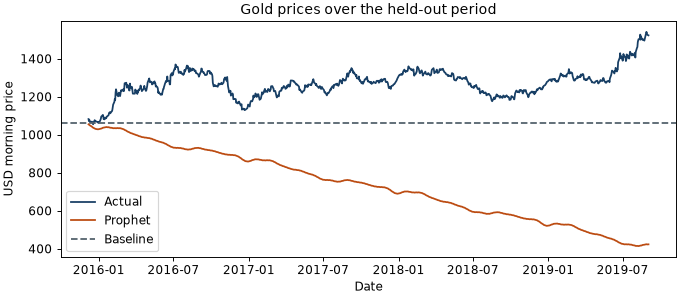

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.plot(results["ds"], results["y"], label="Actual", color="#183f65")
ax.plot(results["ds"], results["yhat"], label="Prophet", color="#bc4c12")
ax.axhline(train["y"].iloc[-1], linestyle="--", color="#52616b", label="Baseline")
ax.set(title="Gold prices over the held-out period", xlabel="Date", ylabel="USD morning price")
ax.legend()
plt.show()

## Interpretation

This is a single historical holdout. The constant-price baseline helps show whether the seasonal model improved on a simple forecast for this particular period. A rolling evaluation would test whether that comparison holds across several time windows.